# Lab 5: Motor parameter identification

**Sanjar, ID 240048**

I recorded `steps_M4_240048.txt` and `steps_M3_240048.txt` on the physical robot.
PWM changes from -100% to +100% in 10% steps, with 2 seconds powered and 1 second
coasting. The battery voltage used is 11.8 V for M4 (before and after its run)
and 11.6 V for the new M3 run.

Both files contain changing encoder readings at all 20 nonzero PWM levels.
Keep both data files beside this notebook; in Colab, upload them when prompted.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, OptimizeWarning
from scipy.integrate import odeint
from IPython.display import display

filenames = {'M4': 'steps_M4_240048.txt', 'M3': 'steps_M3_240048.txt'}
data_dir = Path('motor_data') if Path('motor_data').is_dir() else Path('.')
missing = [name for name in filenames.values() if not (data_dir / name).is_file()]
if missing:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place the raw files beside this notebook: ' + ', '.join(missing))
    files.upload()
    data_dir = Path('.')
    missing = [name for name in filenames.values() if not (data_dir / name).is_file()]
    if missing:
        raise FileNotFoundError('Still missing: ' + ', '.join(missing))

battery = {'M4': 11.8, 'M3': 11.6}
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Speed and time constant at every PWM level

I convert angle to radians and time to seconds, subtract the first angle and time of
each powered segment, and fit:

$$\theta(t)=\omega_{ss}(t-T_m+T_m e^{-t/T_m}).$$

Here $\omega_{ss}$ is steady-state speed in rad/s and $T_m$ is the time constant in
seconds. Voltage is $U=\mathrm{PWM}/100\times U_{battery}$, using each motor's reading. Fits shorter than two sampling
intervals are flagged because the initial acceleration is poorly resolved.

In [2]:
logs = {}
for motor, filename in filenames.items():
    raw = np.loadtxt(data_dir / filename, delimiter=',', ndmin=2)
    if raw.shape[1] != 3 or not np.isfinite(raw).all():
        raise ValueError(f'{filename}: expected angle,time,PWM columns')
    angle_deg, time_ms, pwm = raw.T
    if np.any(np.diff(time_ms) <= 0):
        raise ValueError(f'{filename}: timestamps must increase')
    t = (time_ms - time_ms[0]) / 1000
    angle = np.deg2rad(angle_deg)
    cuts = np.r_[0, np.flatnonzero(np.diff(pwm)) + 1, len(pwm)]
    logs[motor] = {'t': t, 'angle': angle, 'pwm': pwm,
                   'segments': list(zip(cuts[:-1], cuts[1:]))}

def model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

fit_rows = []
step_data = {}
for motor, log in logs.items():
    for a, b in log['segments']:
        level = log['pwm'][a]
        if level == 0:
            continue
        t = log['t'][a:b] - log['t'][a]
        theta = log['angle'][a:b] - log['angle'][a]
        dt = np.median(np.diff(t))
        row = {'Motor': motor, 'PWM': level, 'U_V': level / 100 * battery[motor],
               'n': b-a, 'duration_s': t[-1], 'angle_range_deg': np.rad2deg(np.ptp(theta)),
               'w_ss': np.nan, 'T_m': np.nan, 'w_error': np.nan, 'T_error': np.nan,
               'RMSE_rad': np.nan, 'status': 'no encoder change'}
        step_data[(motor, level)] = (t, theta)
        if np.ptp(theta) > 0:
            tail = max(5, len(t) // 5)
            guess = np.polyfit(t[-tail:], theta[-tail:], 1)[0]
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('error', OptimizeWarning)
                    values, cov = curve_fit(model, t, theta, p0=[guess, 0.1],
                        bounds=([-np.inf, 0.0001], [np.inf, 2]), maxfev=20000)
                errors = np.sqrt(np.diag(cov))
                status = 'ok'
                if not np.isfinite(errors).all():
                    status = 'uncertainty unavailable'
                elif values[1] <= 0.00011 or values[1] >= 1.99:
                    status = 'T_m at fit bound'
                elif values[1] < 2 * dt:
                    status = 'T_m poorly resolved in time'
                elif errors[1] > values[1]:
                    status = 'large T_m uncertainty'
                row.update(w_ss=values[0], T_m=values[1], w_error=errors[0],
                    T_error=errors[1], RMSE_rad=np.sqrt(np.mean((theta-model(t, *values))**2)),
                    status=status)
            except (RuntimeError, ValueError, OptimizeWarning) as error:
                row['status'] = 'fit failed: ' + str(error)
        fit_rows.append(row)

results = pd.DataFrame(fit_rows).sort_values(['Motor', 'PWM']).reset_index(drop=True)

for motor in filenames:
    valid = results[(results.Motor == motor) & results.w_ss.notna()]
    if valid.empty:
        print(f'{motor}: no usable encoder changes; parameters cannot be fitted.')
    else:
        print(f'{motor}: speed in rad/s; time constant in seconds')
        display(valid[['PWM', 'U_V', 'w_ss', 'T_m', 'status']].round(4))

M4: speed in rad/s; time constant in seconds


,PWM,U_V,w_ss,T_m,status
20,-100.0,-11.80,-14.5079,0.0311,T_m poorly resolved in time
21,-90.0,-10.62,-13.2522,0.0545,T_m poorly resolved in time
22,-80.0,-9.44,-12.1969,0.0713,ok
23,-70.0,-8.26,-11.1135,0.1254,ok
24,-60.0,-7.08,-10.0357,0.1407,ok
25,-50.0,-5.90,-9.1650,0.1747,ok
26,-40.0,-4.72,-8.4011,0.1760,ok
27,-30.0,-3.54,-6.9773,0.2092,ok
28,-20.0,-2.36,-5.6430,0.2396,ok
29,-10.0,-1.18,-3.9887,0.2929,ok


M3: speed in rad/s; time constant in seconds


,PWM,U_V,w_ss,T_m,status
0,-100.0,-11.60,-15.1633,0.0357,T_m poorly resolved in time
1,-90.0,-10.44,-14.1268,0.0642,ok
2,-80.0,-9.28,-13.2033,0.0821,ok
3,-70.0,-8.12,-12.1703,0.0927,ok
4,-60.0,-6.96,-11.2369,0.1663,ok
5,-50.0,-5.80,-10.3472,0.1928,ok
6,-40.0,-4.64,-9.6075,0.2061,ok
7,-30.0,-3.48,-8.3499,0.2743,ok
8,-20.0,-2.32,-6.9182,0.3128,ok
9,-10.0,-1.16,-5.2086,0.4494,ok


## 2. Speed against voltage

I fit a line separately for positive and negative rotation, using the 20-70% PWM
range. The slope gives an effective $k_e$; the intercept is kept because the data
do not follow a line through zero. Both motors move at ±10%, so finer input steps are
needed to locate the dead zone.

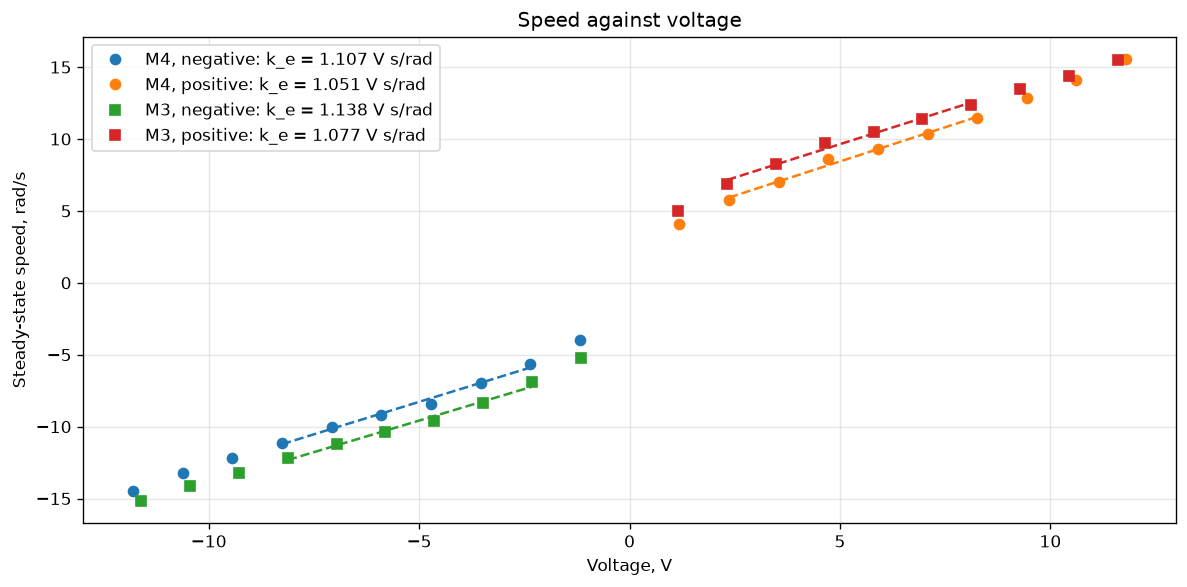

In [3]:
summary_rows = []
plt.figure()
for motor in filenames:
    for direction, sign in [('negative', -1), ('positive', 1)]:
        group = results[(results.Motor == motor) & (np.sign(results.PWM) == sign)
                        & results.w_ss.notna()].sort_values('PWM')
        if group.empty:
            continue
        middle = group[group.PWM.abs().between(20, 70)]
        slope, intercept = np.polyfit(middle.U_V, middle.w_ss, 1)
        k_e = 1 / abs(slope)
        points = plt.plot(group.U_V, group.w_ss, 'o' if motor == 'M4' else 's',
                         label=f'{motor}, {direction}: k_e = {k_e:.3f} V s/rad')
        U = np.linspace(middle.U_V.min(), middle.U_V.max(), 100)
        plt.plot(U, slope*U+intercept, '--', color=points[0].get_color())
        summary_rows.append({'Motor': motor, 'Direction': direction, 'k_e': k_e})
summary = pd.DataFrame(summary_rows)
plt.xlabel('Voltage, V')
plt.ylabel('Steady-state speed, rad/s')
plt.title('Speed against voltage')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Time constant against voltage

The ideal model assumes a constant time constant. The plot compares the fitted
values for both motors. The fastest responses are difficult to resolve when
only a few samples cover the acceleration. Error bars show fitting standard errors.


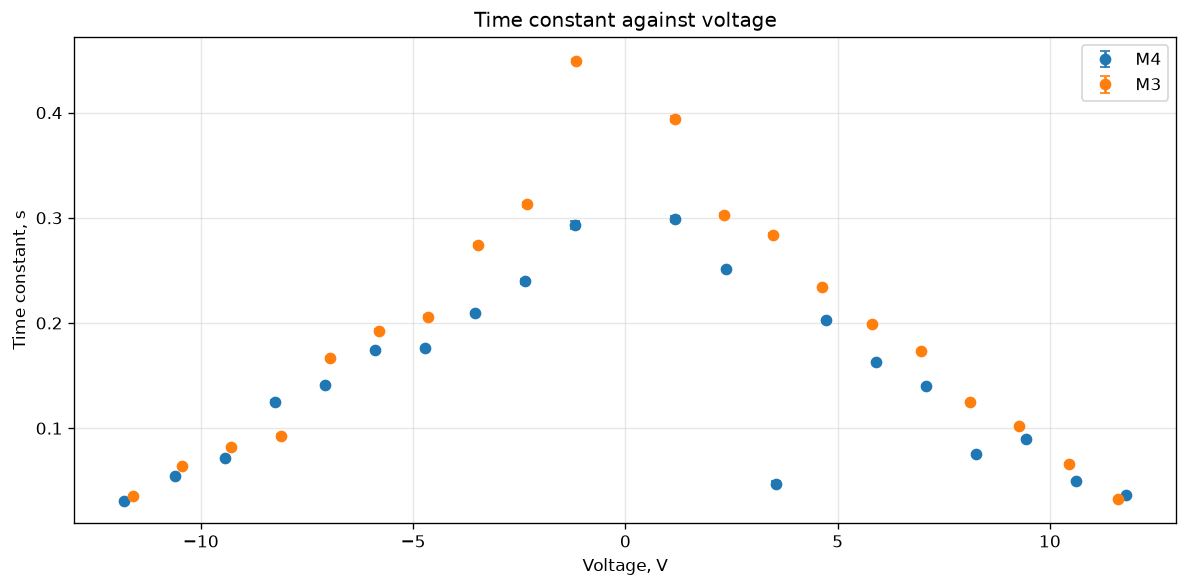

In [4]:
plt.figure()
for motor in filenames:
    valid = results[(results.Motor == motor) & results.T_m.notna()]
    if valid.empty:
        continue
    plt.errorbar(valid.U_V, valid.T_m, yerr=valid.T_error, fmt='o',
                 capsize=3, label=motor)
plt.xlabel('Voltage, V')
plt.ylabel('Time constant, s')
plt.title('Time constant against voltage')
plt.legend()
plt.tight_layout()
plt.show()

## 4. One step: measured and simulated

For M4 at +50% PWM, I solve the motor equations with the fitted $T_m$ and
$k_e=U/\omega_{ss}$. This uses the same step for fitting and comparison, so it is
a fit check rather than independent validation.

T_m = 0.1632 s; step-specific k_e = 0.6350 V s/rad
Angle RMSE = 0.0125 rad


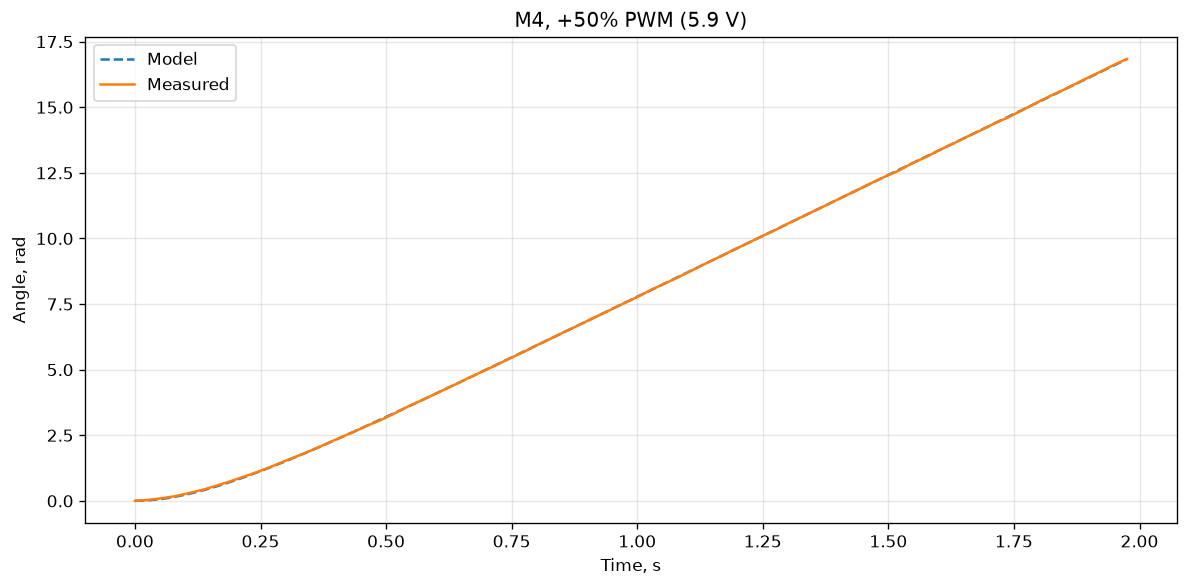

In [5]:
selected = results[(results.Motor == 'M4') & (results.PWM == 50)].iloc[0]
t, theta = step_data[('M4', 50)]
T_m = selected.T_m
U = 0.5 * battery['M4']
k_e_step = U / selected.w_ss

def motor(state, t):
    speed, angle = state
    return [-speed/T_m + U/(T_m*k_e_step), speed]

simulated = odeint(motor, [0, 0], t)
rmse = np.sqrt(np.mean((theta-simulated[:, 1])**2))
print(f'T_m = {T_m:.4f} s; step-specific k_e = {k_e_step:.4f} V s/rad')
print(f'Angle RMSE = {rmse:.4f} rad')
plt.figure()
plt.plot(t, simulated[:, 1], '--', label='Model')
plt.plot(t, theta, label='Measured')
plt.xlabel('Time, s')
plt.ylabel('Angle, rad')
plt.title('M4, +50% PWM (5.9 V)')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Conclusions

M4 speed increases with voltage, but the positive and negative directions are not
identical. At ±100% PWM, the fitted speed magnitudes are about 15.57 and 14.51 rad/s.
The time constant also varies with input, so a single constant does not describe
every step equally well. The +50% model closely matches the step used to fit it.

The new M3 recording contains encoder changes at every tested nonzero PWM level,
so both motors can now be compared in the plots. Their voltage axes use their
respective battery readings, 11.8 V for M4 and 11.6 V for M3. One run per motor
does not establish repeatability; repeated runs and complex-signal validation
are still pending.
